In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import tqdm
import os
import glob
import shutil

import sys
sys.path.append('../../vision')

import training_loop
import losses
import models
import optimizers
import datasets

if torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')
print(device)

cuda:0


In [2]:
class EmbeddingDataset():
    def __init__(self, path='./embeddings'):
        self.path = path
        self.data = sorted(glob.glob(f'{path}/*x.npy'))
        self.label = sorted(glob.glob(f'{path}/*y.npy'))
        self.shape = np.mean(np.load(self.data[0]), axis=0).flatten().shape
        self.length = len(self.data)
        print(f'shape = {self.shape}')
        print(f'length = {len(self.data)}')
    
    def __len__(self):
        return self.length
    
    def __getitem__(self, idx):
        data = np.load(self.data[idx])
        label = np.load(self.label[idx])
        data = torch.tensor(np.mean(data, axis=0), dtype=torch.float32).flatten()
        label = torch.tensor(label, dtype=torch.float32)
        return {'data':data, 'label':label, 'acc':os.path.basename(self.data[idx]).split('-')[0]}

In [3]:
# for path in tqdm.tqdm(glob.glob('./train_embeddings/*x.npy')):
#     try:
#         if len(np.load(path)) == 1:
#             os.remove(path)
#     except:
#         print(path)
#         os.remove(path)

In [4]:
tvdataset = EmbeddingDataset(path='./train_embeddings_firstpass')
train_dataset, val_dataset = torch.utils.data.random_split(tvdataset, [int(0.9*len(tvdataset)), len(tvdataset)-int(0.9*len(tvdataset))])
test_dataset = EmbeddingDataset(path='./test_embeddings_firstpass')

shape = (197376,)
length = 4103
shape = (197376,)
length = 474


In [3]:
train_dataset = EmbeddingDataset(path='./train_embeddings')
val_dataset = EmbeddingDataset(path='./val_embeddings')
test_dataset = EmbeddingDataset(path='./test_embeddings')

shape = (197376,)
length = 5259
shape = (197376,)
length = 353
shape = (197376,)
length = 811


In [6]:
train_dataset[0]

{'data': tensor([-0.0305,  0.0388, -0.1408,  ..., -0.0585,  0.0302, -0.1264]),
 'label': tensor([[0.2250, 0.0000, 0.5714]]),
 'acc': '30891406'}

In [13]:
train_dataset = EmbeddingDataset(path='/data/trevor/overflow/deep_tee_embeddings/train_embeddings_2')
val_dataset = EmbeddingDataset(path='/data/trevor/overflow/deep_tee_embeddings/val_embeddings_2')
test_dataset = EmbeddingDataset(path='./test_embeddings')

shape = (197376,)
length = 4674
shape = (197376,)
length = 312
shape = (197376,)
length = 811


In [6]:
train_dataset[0]

{'data': tensor([-0.0305,  0.0388, -0.1408,  ..., -0.0585,  0.0302, -0.1264]),
 'label': tensor([[0.2250, 0.0000, 0.5714]]),
 'acc': '30891406'}

In [15]:
# empties = []
# for sample in tqdm.tqdm(train_dataset):
#     data = sample['data']
#     if data.shape[0] == 1:
#         empties.append(sample)
# print(len(empties))

# for empty in empties:
#     paths = glob.glob(f'val_embeddings/{empty["acc"]}*')
#     for path in paths:
#         os.remove(path)

In [18]:
len(train_dataset)

5259

In [7]:
import torch.nn as nn

class SimpleMLP(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, dropout=0.2):
        super(SimpleMLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout)
        self.relu = nn.ReLU()
    
    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.dropout(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.dropout(out)
        out = self.fc3(out)
        # out = nn.Sigmoid()(out)
        return out

model = SimpleMLP(np.product(test_dataset.shape), 256, 3)
print(model)

SimpleMLP(
  (fc1): Linear(in_features=197376, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=3, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (relu): ReLU()
)


In [10]:
optimizer = torch.optim.AdamW(model.parameters(), lr=0.00001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0.0,)

loss_fn = losses.SimpleLoss()

training_loop.simple_training_loop(
    run_dir             = '../experiments/mlp_test4',  # Output directory.
    dataset             = train_dataset,                # Options for training set.
    validation_dataset  = test_dataset,                 # Options for training set.
    network             = model,                        # Options for model and preconditioning.
    loss                = loss_fn,                      # Options for loss function.
    optimizer           = optimizer,                    # Options for optimizer.
    seed                = 0,                            # Global random seed.
    batch_size          = 64,                           # Total batch size for one training iteration.
    num_workers         = 16,                            # Number of data loading workers.
    total_kimg          = 1000,                          # Training duration, measured in thousands of training images.
    kimg_per_tick       = 1,                           # How often to log training and validation stats.
    kimg_per_save       = 1,                           # How often to save the training state.
    device              = torch.device('cuda'),
)

Loading dataset...
Constructing network...
Setting up optimizer...
Setting up logs...
Training for 1000 kimg...

saved to training-state-000001.pt
tick 16, loss 0.062063, std 0.042875, valloss 0.043889, valstd 0.006146, time 93.12 sec
saved to training-state-000002.pt
tick 32, loss 0.047916, std 0.005884, valloss 0.039786, valstd 0.006898, time 80.10 sec
saved to training-state-000003.pt
tick 48, loss 0.044696, std 0.006333, valloss 0.037994, valstd 0.005890, time 81.69 sec
saved to training-state-000004.pt
tick 64, loss 0.041859, std 0.006039, valloss 0.037266, valstd 0.006367, time 83.85 sec
saved to training-state-000005.pt
tick 80, loss 0.051853, std 0.036191, valloss 0.037410, valstd 0.006279, time 82.67 sec
saved to training-state-000006.pt
tick 96, loss 0.039558, std 0.007010, valloss 0.036134, valstd 0.005187, time 83.05 sec
saved to training-state-000007.pt
tick 112, loss 0.040352, std 0.006377, valloss 0.035079, valstd 0.005493, time 81.83 sec
saved to training-state-000008.p

In [4]:
import json
log = json.load(open('/home/trevor/repos/deep_TEE/tasks/experiments/mlp_test4/log.json', 'r'))

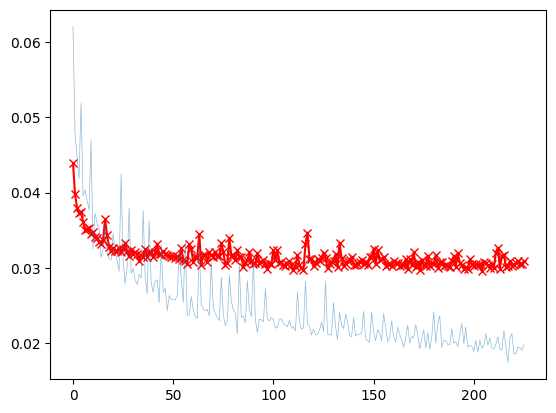

In [5]:
plt.plot( [i for i in log['valloss'] if not np.isnan(i)], c='r', marker='x')
plt.plot(log['loss'][::1], linewidth=0.5, alpha=0.5)

In [8]:
# model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/mlp_test1/*.pt'))[3])['net'].to(device).eval()
# model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/mlp_test2/*.pt'))[6])['net'].to(device).eval()
model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/mlp_test4/*.pt'))[-2])['net'].to(device).eval()

In [9]:
preds = []
labels = []
for embedding in tqdm.tqdm(test_dataset):
    data = embedding['data'].to(device)
    label = embedding['label'].to(device)
    out = model(data)
    preds.append(out.cpu().detach().numpy())
    labels.append(label.cpu().detach().numpy().squeeze())
    
preds = np.array(preds)
labels = np.array(labels)

100%|██████████| 811/811 [00:05<00:00, 152.93it/s]


In [10]:
labels.shape

(811, 3)

Text(0.45, 0.1, "Pearson's r = 0.44")

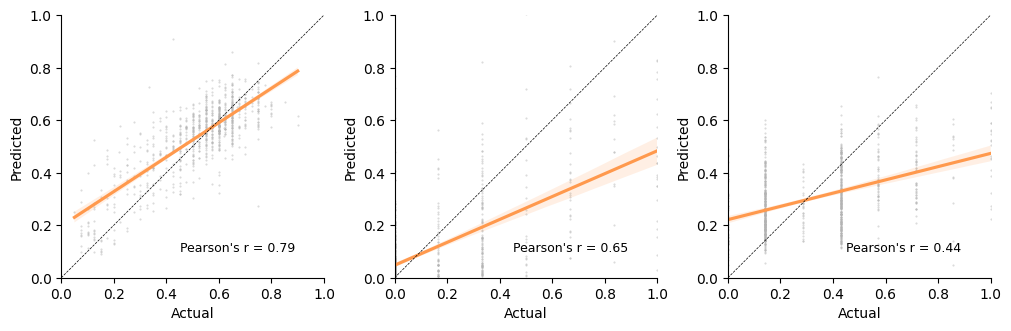

In [11]:
import seaborn as sns

fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xlim([0,1])
    a.set_ylim([0,1])

from scipy import stats
res = stats.pearsonr(labels[:,0], preds[:,0])
sns.regplot(x=labels[:,0], y=preds[:,0], marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(labels[:,1], preds[:,1])
sns.regplot(x=labels[:,1], y=preds[:,1], marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(labels[:,2], preds[:,2])
sns.regplot(x=labels[:,2], y=preds[:,2], marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

Text(0.45, 0.1, "Pearson's r = 0.50")

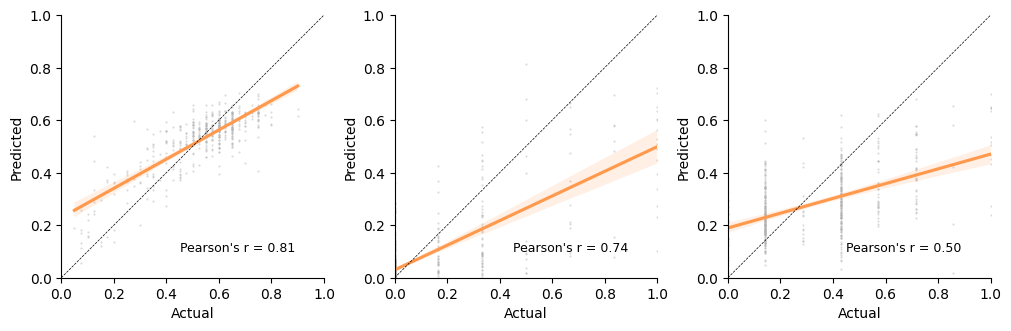

In [13]:
import seaborn as sns

fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xlim([0,1])
    a.set_ylim([0,1])

from scipy import stats
res = stats.pearsonr(labels[:,0], preds[:,0])
sns.regplot(x=labels[:,0], y=preds[:,0], marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(labels[:,1], preds[:,1])
sns.regplot(x=labels[:,1], y=preds[:,1], marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(labels[:,2], preds[:,2])
sns.regplot(x=labels[:,2], y=preds[:,2], marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

In [12]:
import itertools
from sklearn.metrics import auc, roc_curve, confusion_matrix, ConfusionMatrixDisplay


def plot_confusion_matrix(cm, classes, cm2, 
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar(shrink=0.8)
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90, fontsize=11)
    plt.yticks(tick_marks, classes, fontsize=11)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm2[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=11)

    # plt.tight_layout()
    plt.ylabel('True label', fontsize=11)
    plt.xlabel('Predicted label', fontsize=11)

Normalized confusion matrix
[[0.84545455 0.12363636 0.02181818 0.00181818 0.00363636 0.00363636
  0.        ]
 [0.52542373 0.30508475 0.13559322 0.03389831 0.         0.
  0.        ]
 [0.3539823  0.32743363 0.21238938 0.08849558 0.00884956 0.00884956
  0.        ]
 [0.36       0.24       0.16       0.12       0.08       0.
  0.04      ]
 [0.10344828 0.20689655 0.34482759 0.20689655 0.10344828 0.03448276
  0.        ]
 [0.08333333 0.08333333 0.16666667 0.25       0.33333333 0.08333333
  0.        ]
 [0.04347826 0.17391304 0.26086957 0.26086957 0.08695652 0.17391304
  0.        ]]


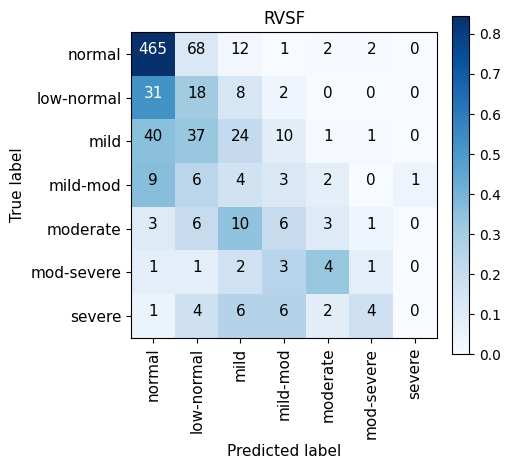

In [13]:
class_names = ['normal','low-normal','mild','mild-mod','moderate','mod-severe','severe']
# class_names = ['absent','trace','trace-mild','mild','mild-moderate','moderate','moderate-severe','severe']

test_labels, test_labels_predicted = np.array(labels[:,1] * 6), np.clip(np.round(preds[:,1] * 6), 0, 6)
    
# Compute confusion matrix
cm = confusion_matrix(test_labels, test_labels_predicted, normalize='true')
cm2 = confusion_matrix(test_labels, test_labels_predicted)

# Plot normalized confusion matrix
plt.figure(figsize = (5, 5), constrained_layout=True)
plot_confusion_matrix(cm=cm, classes=class_names, cm2=cm2, normalize=True,
                      title='RVSF')

plt.savefig('RVSF_prediction_confusion_matrix.png', dpi=300)

Normalized confusion matrix
[[0.04545455 0.52272727 0.22727273 0.20454545 0.         0.
  0.         0.        ]
 [0.00314465 0.3836478  0.42138365 0.16037736 0.03144654 0.
  0.         0.        ]
 [0.         0.34375    0.46875    0.1875     0.         0.
  0.         0.        ]
 [0.         0.24727273 0.40727273 0.29818182 0.04363636 0.00363636
  0.         0.        ]
 [0.         0.05454545 0.41818182 0.34545455 0.16363636 0.01818182
  0.         0.        ]
 [0.         0.01851852 0.37037037 0.37037037 0.18518519 0.03703704
  0.         0.01851852]
 [0.08333333 0.08333333 0.08333333 0.25       0.5        0.
  0.         0.        ]
 [0.         0.         0.19047619 0.23809524 0.38095238 0.19047619
  0.         0.        ]]


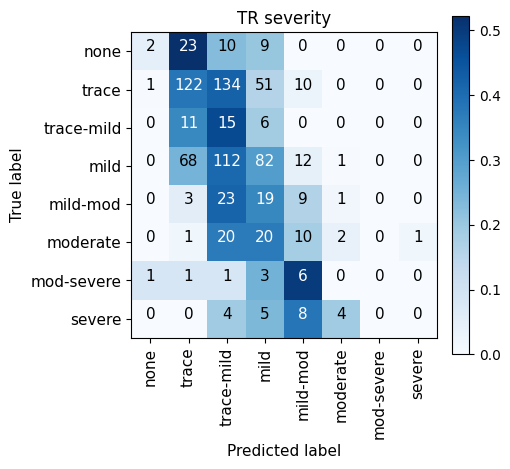

In [14]:
# class_names = ['absent','trace','trace-mild','mild','mild-moderate','moderate','severe']
class_names = ['none','trace','trace-mild','mild','mild-mod','moderate','mod-severe','severe']

test_labels, test_labels_predicted = np.array(labels[:,2] * 7), np.clip(np.round(preds[:,2] * 7), 0, 7)
    
# Compute confusion matrix
cm = confusion_matrix(test_labels, test_labels_predicted, normalize='true')
cm2 = confusion_matrix(test_labels, test_labels_predicted)

# Plot normalized confusion matrix
plt.figure(figsize = (5, 5), constrained_layout=True)
plot_confusion_matrix(cm=cm, classes=class_names, cm2=cm2, normalize=True,
                      title='TR severity')

plt.savefig('TR_prediction_confusion_matrix.png', dpi=300)

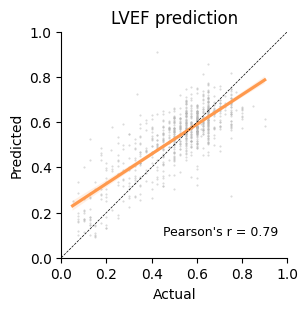

In [15]:
import seaborn as sns

fig, ax = plt.subplots(1,1, figsize=(3,3), layout="constrained")
ax.spines[['right', 'top']].set_visible(False)
ax.set_aspect('equal')
ax.set_xlim([0,1])
ax.set_ylim([0,1])

from scipy import stats
res = stats.pearsonr(labels[:,0], preds[:,0])
sns.regplot(x=labels[:,0], y=preds[:,0], marker='.', ax=ax, scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax.plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax.set_aspect('equal')
ax.set_ylabel('Predicted')
ax.set_xlabel('Actual')
ax.text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax.set_title('LVEF prediction')
plt.savefig('LV_EF_prediction.png', dpi=300)

Text(0.45, 0.1, "Pearson's r = 0.44")

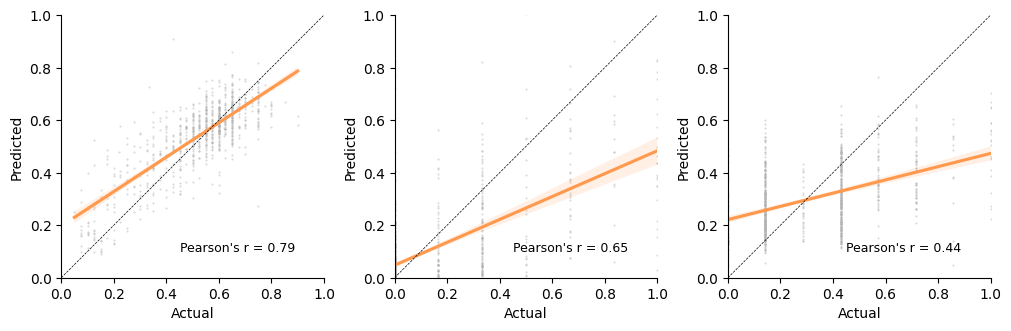

In [16]:
import seaborn as sns

fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xlim([0,1])
    a.set_ylim([0,1])

from scipy import stats
res = stats.pearsonr(labels[:,0], preds[:,0])
sns.regplot(x=labels[:,0], y=preds[:,0], marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(labels[:,1], preds[:,1])
sns.regplot(x=labels[:,1], y=preds[:,1], marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(labels[:,2], preds[:,2])
sns.regplot(x=labels[:,2], y=preds[:,2], marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0.1,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

cutoffs:

LVEF: 55 and 40 and 30, normal +, moderate +, severe +
RVSF: 0 and 4 and 6, normal +, moderate +
TR: 0 and 5 and 7, normal, moderate, severe

Logistic: ROC AUC=0.860
Logistic: ROC AUC=0.952
Logistic: ROC AUC=0.820
Logistic: ROC AUC=0.916
Logistic: ROC AUC=0.689
Logistic: ROC AUC=0.786


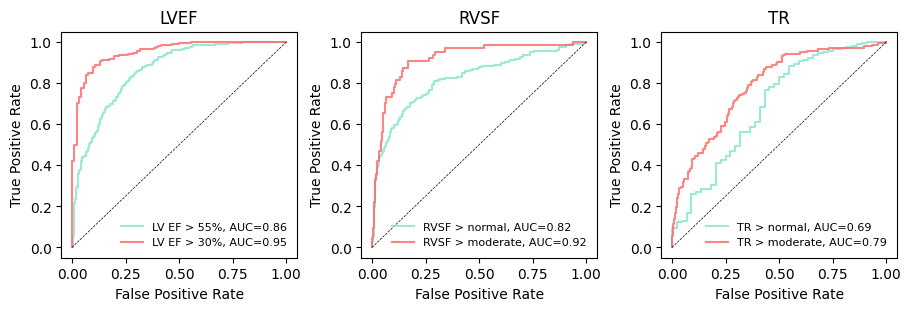

In [17]:
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

fig, ax = plt.subplots(1,3, figsize=(9,3), layout="constrained")

y50 = [v > 0.55 for v in labels[:,0]]
y25 = [v > 0.30 for v in labels[:,0]]

testy, predy = y50, preds[:,0]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[0].plot(fpr, tpr, label='LV EF > 55%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

testy, predy = y25, preds[:,0]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[0].plot(fpr, tpr, label='LV EF > 30%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].legend(fontsize=8, frameon=False)
ax[0].set_ylabel('True Positive Rate')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_title('LVEF')


y50 = [v > 0.071 for v in labels[:,1]]
y25 = [v > 0.5 for v in labels[:,1]]

testy, predy = y50, preds[:,1]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='RVSF > normal, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

testy, predy = y25, preds[:,1]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='RVSF > moderate, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].legend(fontsize=8, frameon=False)
ax[1].set_ylabel('True Positive Rate')
ax[1].set_xlabel('False Positive Rate')
ax[1].set_title('RVSF')


y50 = [v > 0.11 for v in labels[:,2]]
y25 = [v > 0.55 for v in labels[:,2]]

testy, predy = y50, preds[:,2]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[2].plot(fpr, tpr, label='TR > normal, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

testy, predy = y25, preds[:,2]
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[2].plot(fpr, tpr, label='TR > moderate, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].legend(fontsize=8, frameon=False)
ax[2].set_ylabel('True Positive Rate')
ax[2].set_xlabel('False Positive Rate')
ax[2].set_title('TR')

#add horizontal gap between plots
plt.savefig('ROC_curves.png', dpi=300)

In [ ]:
y50 = [v > 0.5 for v in preds[:,0]]

In [ ]:
preds[:,0]

array([0.5352507 , 0.5870379 , 0.56159776, 0.5606366 , 0.558416  ,
       0.49391115, 0.5545995 , 0.6317878 , 0.25349557, 0.61414766,
       0.6276615 , 0.5651243 , 0.65340924, 0.5942483 , 0.5194135 ,
       0.51294875, 0.5734456 , 0.6013756 , 0.25921395, 0.13498278,
       0.19934288, 0.5369285 , 0.6357552 , 0.65672714, 0.54226446,
       0.5747917 , 0.5885863 , 0.57803833, 0.5697487 , 0.51749617,
       0.4736739 , 0.5793212 , 0.57309514, 0.34968692, 0.58275515,
       0.5774095 , 0.55649364, 0.6241994 , 0.62706596, 0.6258053 ,
       0.48358124, 0.57798725, 0.54220897, 0.55359447, 0.6299178 ,
       0.6565867 , 0.58805764, 0.69871545, 0.4590704 , 0.42471847,
       0.56708986, 0.55039406, 0.53976864, 0.2985175 , 0.50840193,
       0.5615578 , 0.4780819 , 0.54198563, 0.589079  , 0.7025774 ,
       0.6602729 , 0.6242699 , 0.378464  , 0.5111936 , 0.5699433 ,
       0.62253994, 0.51313317, 0.5165331 , 0.62475795, 0.60111487,
       0.506241  , 0.52007157, 0.5742937 , 0.5914518 , 0.53793